In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sales = pd.read_csv("../data/processed/sales_cleaned.csv")

sales['Date'] = pd.to_datetime(sales['Date'])

print("Dataset loaded:", sales.shape)

Dataset loaded: (421570, 21)


In [3]:
total_sales = sales['Weekly_Sales'].sum()
average_weekly_sales = sales['Weekly_Sales'].mean()
total_stores = sales['Store'].nunique()
total_departments = sales['Dept'].nunique()

print(f"Total Sales: ${total_sales:,.2f}")
print(f"Average Weekly Sales: ${average_weekly_sales:,.2f}")
print(f"Total Stores: {total_stores}")
print(f"Total Departments: {total_departments}")

Total Sales: $6,737,218,987.11
Average Weekly Sales: $15,981.26
Total Stores: 45
Total Departments: 81


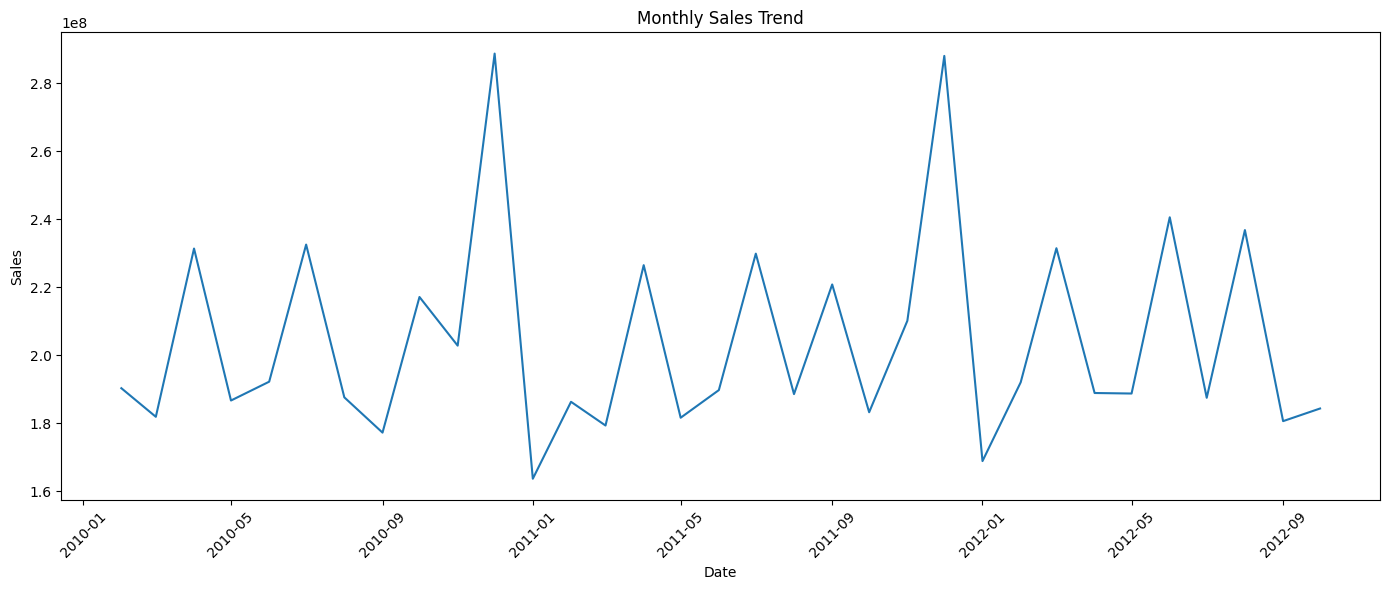

In [4]:
monthly_sales = (
    sales.groupby(sales['Date'].dt.to_period('M'))['Weekly_Sales']
    .sum()
    .reset_index()
)

monthly_sales['Date'] = monthly_sales['Date'].dt.to_timestamp()

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales['Date'],
    monthly_sales['Weekly_Sales']
)

plt.title('Monthly Sales Trend')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [5]:
store_sales = (
    sales.groupby('Store')['Weekly_Sales']
    .sum()
    .sort_values(ascending=False)
)

print(store_sales.head(10))

Store
20    3.013978e+08
4     2.995440e+08
14    2.889999e+08
13    2.865177e+08
2     2.753824e+08
10    2.716177e+08
27    2.538559e+08
6     2.237561e+08
1     2.224028e+08
39    2.074455e+08
Name: Weekly_Sales, dtype: float64


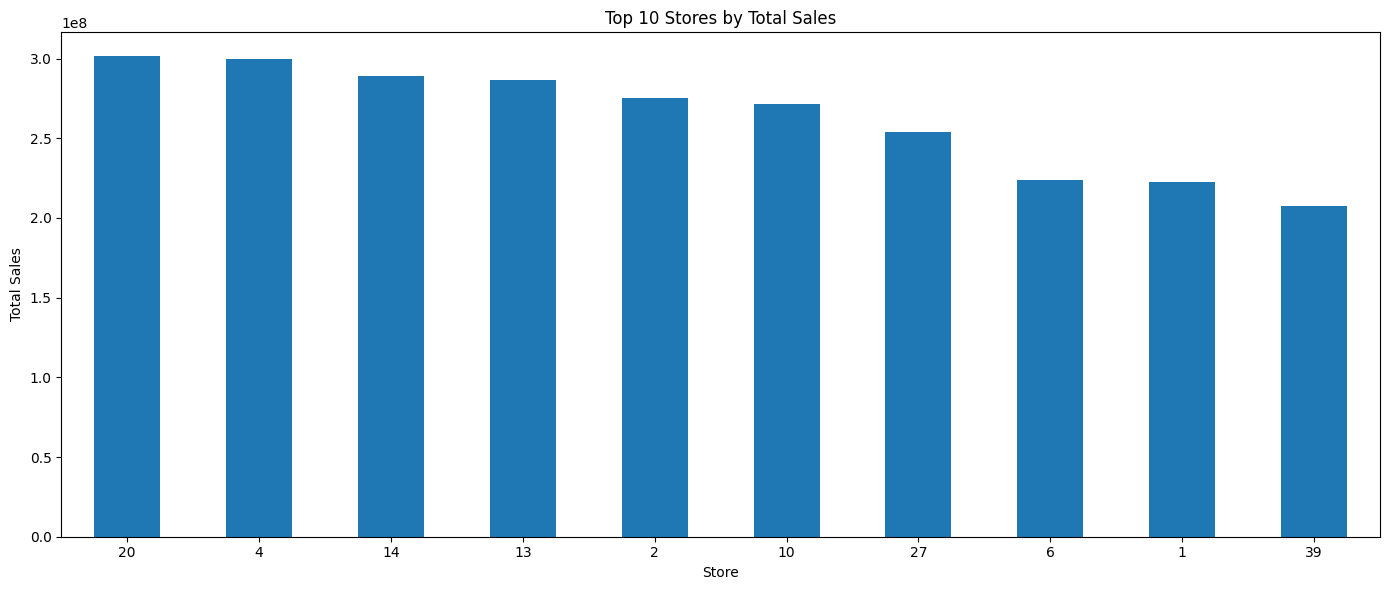

In [6]:
plt.figure(figsize=(14, 6))

store_sales.head(10).plot(kind='bar')

plt.title('Top 10 Stores by Total Sales')
plt.xlabel('Store')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [7]:
dept_sales = (
    sales.groupby('Dept')['Weekly_Sales']
    .sum()
    .sort_values(ascending=False)
)

print(dept_sales.head(10))

Dept
92    4.839433e+08
95    4.493202e+08
38    3.931181e+08
72    3.057252e+08
90    2.910685e+08
40    2.889360e+08
2     2.806112e+08
91    2.167817e+08
13    1.973216e+08
8     1.942808e+08
Name: Weekly_Sales, dtype: float64


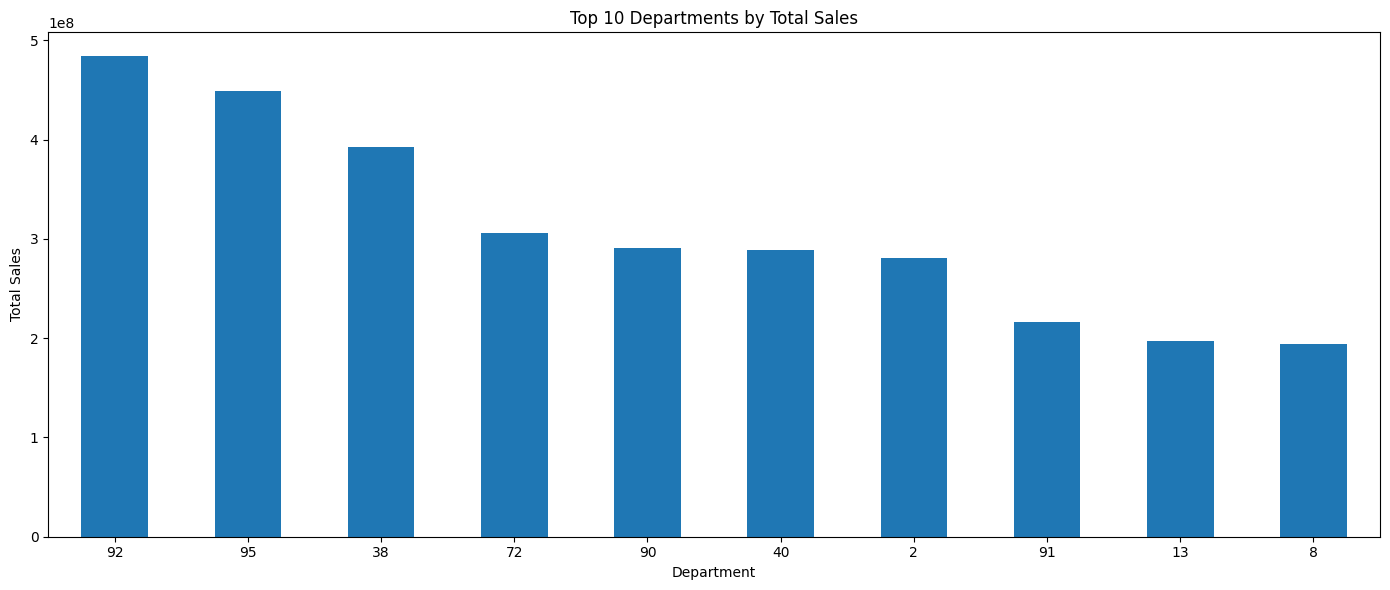

In [8]:
plt.figure(figsize=(14, 6))

dept_sales.head(10).plot(kind='bar')

plt.title('Top 10 Departments by Total Sales')
plt.xlabel('Department')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [9]:
holiday_sales = (
    sales.groupby('IsHoliday')['Weekly_Sales']
    .agg(['sum', 'mean', 'count'])
)

holiday_sales

,sum,mean,count
IsHoliday,,,
False,6.231919e+09,15901.445069,391909
True,5.052996e+08,17035.823187,29661


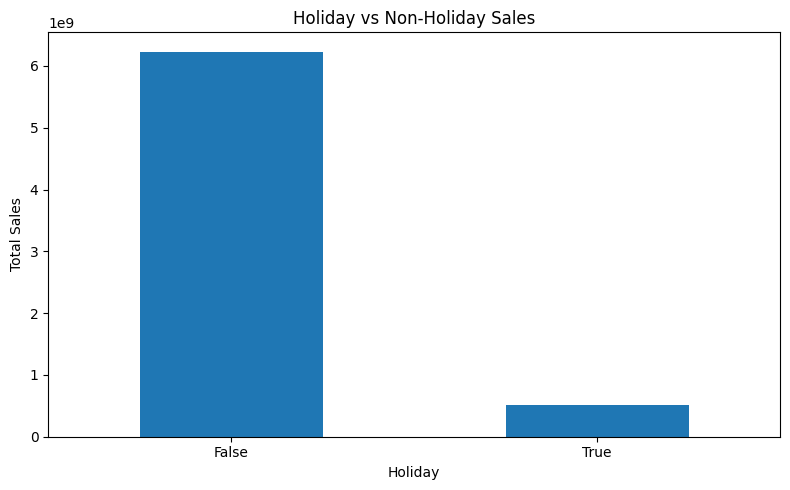

In [10]:
plt.figure(figsize=(8, 5))

sales.groupby('IsHoliday')['Weekly_Sales'].sum().plot(
    kind='bar'
)

plt.title('Holiday vs Non-Holiday Sales')
plt.xlabel('Holiday')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [11]:
month_sales = (
    sales.groupby('Month')['Weekly_Sales']
    .sum()
)

print(month_sales)

Month
1     3.325984e+08
2     5.687279e+08
3     5.927859e+08
4     6.468598e+08
5     5.571256e+08
6     6.226299e+08
7     6.500010e+08
8     6.130902e+08
9     5.787612e+08
10    5.847848e+08
11    4.130157e+08
12    5.768386e+08
Name: Weekly_Sales, dtype: float64


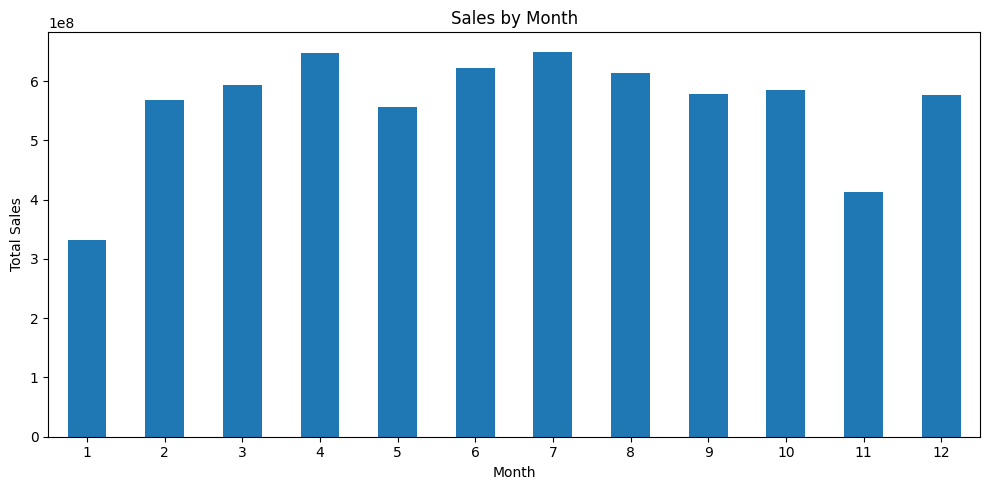

In [12]:
plt.figure(figsize=(10, 5))

month_sales.plot(kind='bar')

plt.title('Sales by Month')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [13]:
type_sales = (
    sales.groupby('Type')['Weekly_Sales']
    .agg(['sum', 'mean', 'count'])
)

type_sales

,sum,mean,count
Type,,,
A,4.331015e+09,20099.568043,215478
B,2.000701e+09,12237.075977,163495
C,4.055035e+08,9519.532538,42597


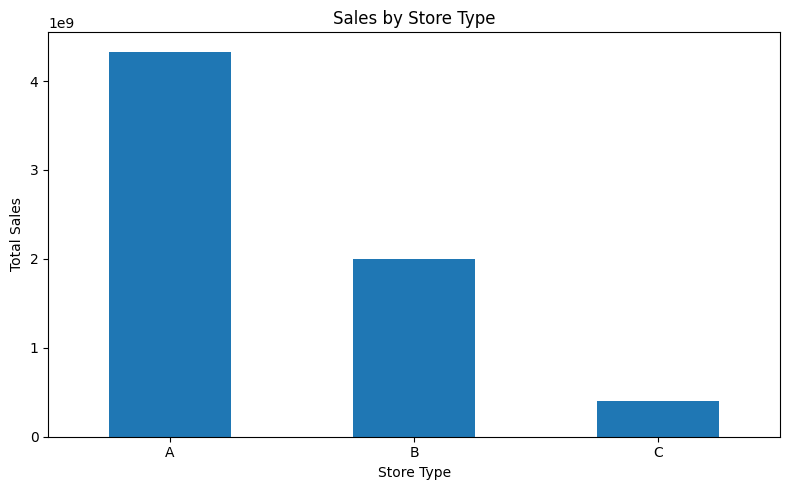

In [14]:
plt.figure(figsize=(8, 5))

sales.groupby('Type')['Weekly_Sales'].sum().plot(
    kind='bar'
)

plt.title('Sales by Store Type')
plt.xlabel('Store Type')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

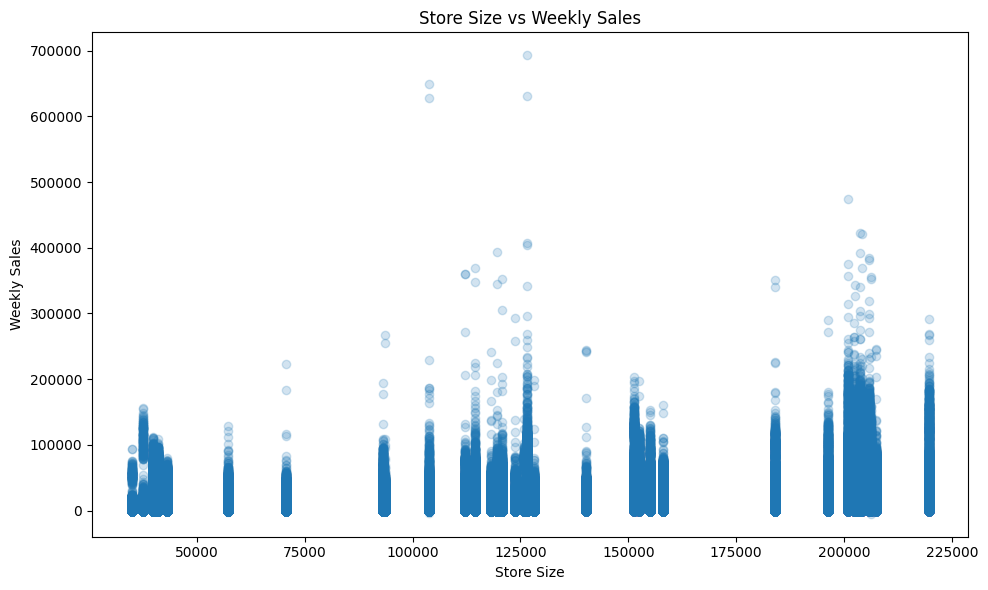

In [15]:
plt.figure(figsize=(10, 6))

plt.scatter(
    sales['Size'],
    sales['Weekly_Sales'],
    alpha=0.2
)

plt.title('Store Size vs Weekly Sales')
plt.xlabel('Store Size')
plt.ylabel('Weekly Sales')
plt.tight_layout()
plt.show()

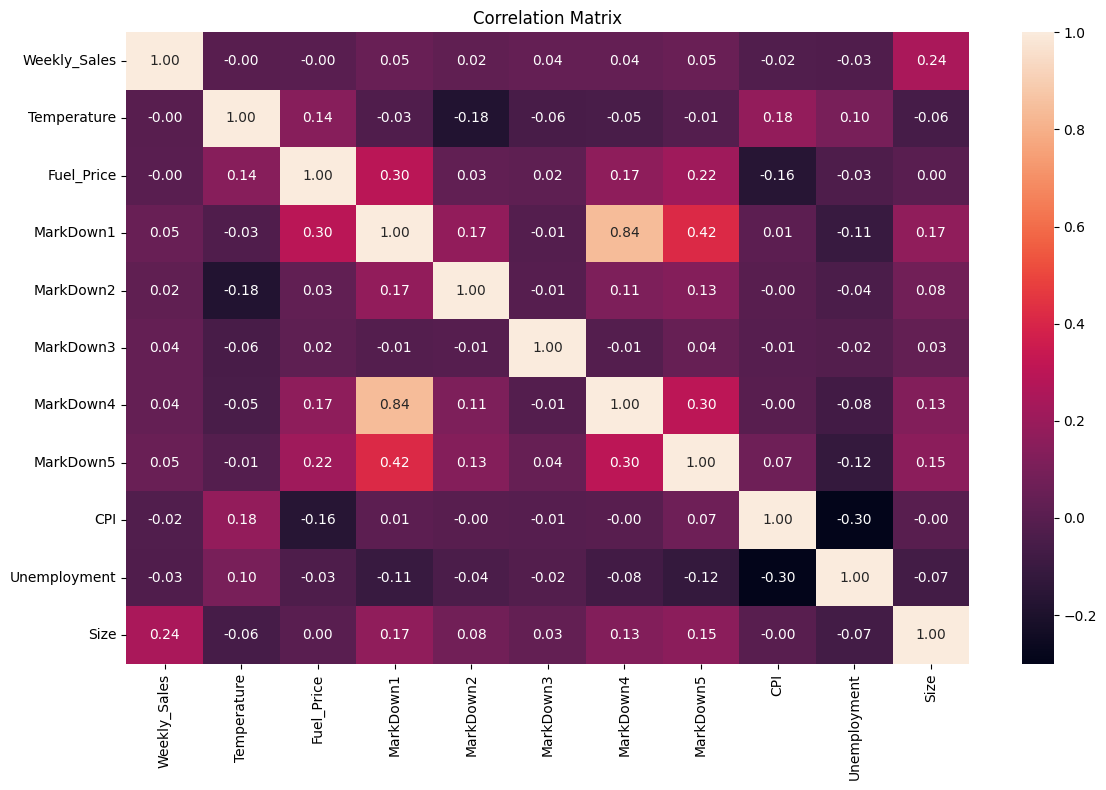

In [16]:
numeric_cols = [
    'Weekly_Sales',
    'Temperature',
    'Fuel_Price',
    'MarkDown1',
    'MarkDown2',
    'MarkDown3',
    'MarkDown4',
    'MarkDown5',
    'CPI',
    'Unemployment',
    'Size'
]

correlation = sales[numeric_cols].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    fmt='.2f'
)

plt.title('Correlation Matrix')
plt.tight_layout()
plt.show()

In [17]:
negative_sales = sales[sales['Weekly_Sales'] < 0]

print("Negative sales records:", len(negative_sales))

print(
    negative_sales['Weekly_Sales'].describe()
)

Negative sales records: 1285
count    1285.000000
mean      -68.608218
std       231.664245
min     -4988.940000
25%       -41.000000
50%       -13.200000
75%        -4.940000
max        -0.020000
Name: Weekly_Sales, dtype: float64


In [18]:
negative_sales.groupby('Dept')['Weekly_Sales'].agg(
    ['count', 'sum', 'min', 'max']
).sort_values('count', ascending=False).head(10)

,count,sum,min,max
Dept,,,,
47,254,-53188.06,-3924.00,-1.50
18,180,-1819.05,-175.54,-0.10
54,146,-4829.81,-465.08,-0.76
19,87,-1042.66,-69.56,-0.97
94,77,-647.78,-173.84,-0.08
80,68,-4231.48,-590.04,-0.04
49,67,-1455.98,-326.61,-1.88
59,44,-411.82,-55.46,-0.36
72,34,-3047.58,-379.00,-5.00


In [19]:
import os

chart_path = "../outputs/charts"
os.makedirs(chart_path, exist_ok=True)

print("Charts folder ready:", chart_path)

Charts folder ready: ../outputs/charts


In [20]:
import os
import matplotlib.pyplot as plt
import seaborn as sns

# Create output folder
chart_path = "../outputs/charts"
os.makedirs(chart_path, exist_ok=True)

# ============================================================
# 1. Monthly Sales Trend
# ============================================================

monthly_sales = (
    sales.groupby(sales['Date'].dt.to_period('M'))['Weekly_Sales']
    .sum()
    .reset_index()
)

monthly_sales['Date'] = monthly_sales['Date'].dt.to_timestamp()

plt.figure(figsize=(14, 6))
plt.plot(
    monthly_sales['Date'],
    monthly_sales['Weekly_Sales']
)

plt.title('Monthly Sales Trend')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    f"{chart_path}/01_monthly_sales_trend.png",
    dpi=300,
    bbox_inches='tight'
)
plt.close()


# ============================================================
# 2. Top 10 Stores
# ============================================================

store_sales = (
    sales.groupby('Store')['Weekly_Sales']
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(14, 6))
store_sales.head(10).plot(kind='bar')

plt.title('Top 10 Stores by Total Sales')
plt.xlabel('Store')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    f"{chart_path}/02_top_10_stores.png",
    dpi=300,
    bbox_inches='tight'
)
plt.close()


# ============================================================
# 3. Top 10 Departments
# ============================================================

dept_sales = (
    sales.groupby('Dept')['Weekly_Sales']
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(14, 6))
dept_sales.head(10).plot(kind='bar')

plt.title('Top 10 Departments by Total Sales')
plt.xlabel('Department')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    f"{chart_path}/03_top_10_departments.png",
    dpi=300,
    bbox_inches='tight'
)
plt.close()


# ============================================================
# 4. Holiday vs Non-Holiday Sales
# ============================================================

plt.figure(figsize=(8, 5))

sales.groupby('IsHoliday')['Weekly_Sales'].sum().plot(
    kind='bar'
)

plt.title('Holiday vs Non-Holiday Sales')
plt.xlabel('Holiday')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    f"{chart_path}/04_holiday_vs_nonholiday_sales.png",
    dpi=300,
    bbox_inches='tight'
)
plt.close()


# ============================================================
# 5. Sales by Month
# ============================================================

month_sales = (
    sales.groupby('Month')['Weekly_Sales']
    .sum()
)

plt.figure(figsize=(10, 5))
month_sales.plot(kind='bar')

plt.title('Sales by Month')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    f"{chart_path}/05_sales_by_month.png",
    dpi=300,
    bbox_inches='tight'
)
plt.close()


# ============================================================
# 6. Sales by Store Type
# ============================================================

plt.figure(figsize=(8, 5))

sales.groupby('Type')['Weekly_Sales'].sum().plot(
    kind='bar'
)

plt.title('Sales by Store Type')
plt.xlabel('Store Type')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    f"{chart_path}/06_sales_by_store_type.png",
    dpi=300,
    bbox_inches='tight'
)
plt.close()


# ============================================================
# 7. Store Size vs Weekly Sales
# ============================================================

plt.figure(figsize=(10, 6))

plt.scatter(
    sales['Size'],
    sales['Weekly_Sales'],
    alpha=0.2
)

plt.title('Store Size vs Weekly Sales')
plt.xlabel('Store Size')
plt.ylabel('Weekly Sales')
plt.tight_layout()

plt.savefig(
    f"{chart_path}/07_store_size_vs_sales.png",
    dpi=300,
    bbox_inches='tight'
)
plt.close()


# ============================================================
# 8. Correlation Matrix
# ============================================================

numeric_cols = [
    'Weekly_Sales',
    'Temperature',
    'Fuel_Price',
    'MarkDown1',
    'MarkDown2',
    'MarkDown3',
    'MarkDown4',
    'MarkDown5',
    'CPI',
    'Unemployment',
    'Size'
]

correlation = sales[numeric_cols].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    fmt='.2f'
)

plt.title('Correlation Matrix')
plt.tight_layout()

plt.savefig(
    f"{chart_path}/08_correlation_matrix.png",
    dpi=300,
    bbox_inches='tight'
)
plt.close()


# ============================================================
# Finished
# ============================================================

print("✅ All 8 EDA charts have been saved successfully!")
print(f"📁 Location: {os.path.abspath(chart_path)}")

✅ All 8 EDA charts have been saved successfully!
📁 Location: D:\DA_intern\Sales-Forecasting-Business-Intelligence-Dashboard\outputs\charts


In [21]:
plt.close()

In [22]:
print(f"Total Sales: ${total_sales:,.2f}")
print(f"Average Weekly Sales: ${average_weekly_sales:,.2f}")
print(f"Total Stores: {total_stores}")
print(f"Total Departments: {total_departments}")

Total Sales: $6,737,218,987.11
Average Weekly Sales: $15,981.26
Total Stores: 45
Total Departments: 81
